# Learning a neural ODE from noisy observations of one coordinate

Can a three-dimensional neural ODE fitted to noisy observations of $x_1$ forecast the next few oscillations and recover the long-run distribution of $x_1$?

### How one time series is generated

For each trajectory $i$, let $\mathbf{x}_i(t)=(x_{i,1}(t),x_{i,2}(t),x_{i,3}(t))^\top$ be its latent state at simulation time $t$. Draw $\mathbf{x}_i(0)$ independently from $\pi_0=\mathcal N((0,0,25)^\top,100I_3)$. The state then follows the deterministic Lorenz–63 equations

$$
\dot x_1=10(x_2-x_1),\qquad
\dot x_2=x_1(28-x_3)-x_2,\qquad
\dot x_3=x_1x_2-\tfrac{8}{3}x_3.
$$

Let $b_i$ be the simulation time when recording begins. Half the trajectories have $b_i=0$ so the records include initial transients. The other half have $b_i=20$ so the system has time to approach its attractor. In both groups the local observation clock starts at $t_k=k\Delta t$ with $t_0=0$. For a record of duration $T$,

$$
y_{ik}=x_{i,1}(b_i+t_k)+\epsilon_{ik},\qquad
\epsilon_{ik}\overset{\mathrm{iid}}{\sim}\mathcal N(0,1),\qquad
\Delta t=0.02,\quad k=0,\ldots,T/\Delta t.
$$

### What the neural ODE learns

The fitted model uses the same three-coordinate notation on the local clock. Write $\mathbf{x}_{\theta,i}(t)$ for its latent state in series $i$ and $x_{\theta,i,1}(t)$ for its first coordinate. All series share a drift $f_\theta:\mathbb R^3\to\mathbb R^3$ and have independent starting states,

$$
\dot{\mathbf{x}}_{\theta,i}(t)=f_\theta(\mathbf{x}_{\theta,i}(t)),\qquad
\mathbf{x}_{\theta,i}(0)\sim\pi_0,\qquad
y_{ik}\mid\mathbf{x}_{\theta,i}(t_k)\sim\mathcal N(x_{\theta,i,1}(t_k),1).
$$

The filter applies $\pi_0$ at the first recorded observation, including for burned-in records. It receives only the scalar observations $y_{ik}$. The Lorenz equations and simulated states are used for data generation and evaluation.

Let $\mathbf{x}_\theta(t;\mathbf{x}_0)$ be the neural ODE solution from a given starting state $\mathbf{x}_0$, with first coordinate $x_{\theta,1}(t;\mathbf{x}_0)$. For a series with $K$ observations, its marginal likelihood averages over that starting state,

$$
p_\theta(y_{i,0:K-1})=\int\prod_{k=0}^{K-1}
\mathcal N\!\left(y_{ik};x_{\theta,1}(t_k;\mathbf{x}_0),1\right)\,\pi_0(d\mathbf{x}_0).
$$

The ensemble Kalman filter (EnKF) approximates this likelihood. For $N$ training series, Adam maximizes the mean approximate log likelihood per observation, $\frac{1}{NK}\sum_{i=1}^{N}\log\widehat p_\theta(y_{i,0:K-1})$.

### Which trajectories are held out?

Each row below uses independent trajectories. The counts are the defaults, and the two recording starts are equally represented in each row.

| Set | Series | Recorded local times | Use |
|---|---:|---|---|
| Training | 2,048 | 0–1.5 (76 observations) | Fit shared weights on minibatches of whole series. |
| Validation | 64 | 0–3 (151 observations) | Select the pilot and checkpoint by EnKF likelihood. |
| Likelihood test | 128 | 0–3 (151 observations) | Compare the selected drift with the true drift using paired filter randomness. |
| Forecast test | 128 | 0–12 | Filter through 4 inclusive, then forecast freely through 12. Score the ensemble mean against latent $x_1$. |

A separate long-run evaluation draws 12 new initial states from $\pi_0$, pairs each start across the two models, discards 50 time units and retains 1,000. We compare the marginal distribution and autocorrelation of $x_1$. The interpretation of the two hidden neural coordinates is unconstrained.

Run the cells in order. Changing `SEED` changes the data, network initialization, training minibatches, filter ensembles and evaluation draws.

The code and plots use `x` as shorthand for the first state coordinate $x_1$.

In [1]:
from dataclasses import dataclass, field
from time import perf_counter

import diffrax
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import optax
from cd_dynamax import adjust_rhs
from scipy.signal import correlate

import dynestyx as dsx

SEED = 0
DT = 0.02
TRAIN_SOLVER_STEP = DT
EVAL_SOLVER_STEP = 0.001
FORECAST_SOLVER_STEP = DT / 2

data_key, model_key, training_key, likelihood_key, forecast_key, rollout_key = jr.split(
    jr.key(SEED), 6
)


def time_grid(duration):
    return DT * jnp.arange(round(duration / DT) + 1)

## Simulate independent series

Each split gets a separate random key. The two calls in `observation_bank` implement the recording starts $b_i=0$ and $b_i=20$. Both return observations on the same local time grid.

In [2]:
TRAIN_PER_GROUP = 1024
VALIDATION_PER_GROUP = 32
TEST_PER_GROUP = 64
TRAIN_DURATION = 1.5
EVALUATION_DURATION = 3.0
BURN_IN = 20.0
OBS_SD = 1.0
PRIOR_SD = 10.0
PRIOR_MEAN = jnp.array([0.0, 0.0, 25.0])
STATE_DIM = len(PRIOR_MEAN)
INITIAL = dist.MultivariateNormal(
    PRIOR_MEAN, covariance_matrix=PRIOR_SD**2 * jnp.eye(STATE_DIM)
)
OBS = dsx.LinearGaussianObservation(
    jnp.array([[1.0, 0.0, 0.0]]), jnp.array([[OBS_SD**2]])
)
DATA_SOLVER = dsx.configs.ODESimulatorConfig(
    stepsize_controller=diffrax.PIDController(rtol=1e-6, atol=1e-7)
)


def dynamics(drift, initial=INITIAL):
    return dsx.DynamicalModel(
        initial_condition=initial,
        state_evolution=dsx.ContinuousTimeStateEvolution(drift=drift),
        observation_model=OBS,
    )


def reference_rhs(state, control, time):
    x, y, z = state
    return jnp.array([10 * (y - x), x * (28 - z) - y, x * y - (8 / 3) * z])


def simulate_data(key, count, duration, burn=0.0):
    result = dsx.simulate(
        dynamics(reference_rhs),
        rng_key=key,
        n_simulations=count,
        predict_times=time_grid(burn + duration),
        simulator_config=DATA_SOLVER,
    )
    first = round(burn / DT)
    return result.observations[:, first:, 0], result.states[:, first:, 0]


def observation_bank(key, count, duration):
    fresh_key, burned_key = jr.split(key)
    fresh, _ = simulate_data(fresh_key, count, duration)
    burned, _ = simulate_data(burned_key, count, duration, burn=BURN_IN)
    return jnp.concatenate([fresh, burned])


train_key, val_key, test_key = jr.split(data_key, 3)
train_y = observation_bank(train_key, TRAIN_PER_GROUP, TRAIN_DURATION)
val_y = observation_bank(val_key, VALIDATION_PER_GROUP, EVALUATION_DURATION)
test_y = observation_bank(test_key, TEST_PER_GROUP, EVALUATION_DURATION)
print(
    f"{len(train_y):,} training series with {train_y.shape[1]} noisy observations each."
)

2,048 training series with 76 noisy observations each.


## Define the neural drift
Specify the hidden layers as a tuple of widths. Scale x using the training data and the two hidden axes using their prior SD. A single estimate of the rate of change of x puts all three network outputs in units of change per time. Apply `adjust_rhs` after converting back to the original state units. Hidden layers start with small random biases and the output layer starts with a zero bias.

In [3]:
HIDDEN_WIDTHS = (100,)
HIDDEN_BIAS_SD = 0.1
RATE_LAG = 5  # Observation intervals used to estimate the rate scale.

x_sd = train_y.std()
state_scale = jnp.full_like(PRIOR_MEAN, PRIOR_SD).at[0].set(x_sd)
increments = train_y[:, RATE_LAG:] - train_y[:, :-RATE_LAG]
rate_scale = increments.std() / (RATE_LAG * DT * x_sd)


def initialize_mlp(key, hidden_widths):
    widths = (STATE_DIM, *hidden_widths, STATE_DIM)
    keys = jr.split(key, len(widths) - 1)
    layers = []
    for fan_in, fan_out, layer_key in zip(widths[:-1], widths[1:], keys, strict=True):
        weight_key, bias_key = jr.split(layer_key)
        weights = jr.normal(weight_key, (fan_in, fan_out)) / jnp.sqrt(fan_in)
        bias = (
            HIDDEN_BIAS_SD * jr.normal(bias_key, (fan_out,))
            if len(layers) < len(hidden_widths)
            else jnp.zeros(fan_out)
        )
        layers.append((weights, bias))
    return layers


def neural_drift(layers):
    def drift(state, control, time):
        hidden = (state - PRIOR_MEAN) / state_scale
        for weights, bias in layers[:-1]:
            hidden = jax.nn.gelu(hidden @ weights + bias)
        weights, bias = layers[-1]
        rate = (hidden @ weights + bias) * rate_scale * state_scale
        return adjust_rhs(state, rate)

    return drift


initial_weights = initialize_mlp(model_key, HIDDEN_WIDTHS)

## Score a series with the EnKF
ODEFlow integrates between consecutive observations using Tsit5. Its training step is the observation spacing. The final likelihood comparison uses the finer evaluation step for both drifts. Each filter gets its own key. Pairing keys during evaluation reduces Monte Carlo noise when comparing the two models.

The earlier tutorial used 0.021 to keep the proposed step just above the 0.02 interval even after floating-point rounding. Here `TRAIN_SOLVER_STEP = DT` expresses the intended time scale directly. Diffrax can take a small final step to reach an interval endpoint.

In [4]:
ENSEMBLE_SIZE = 30
INFLATION = 0.05
FLOW_JITTER = 1e-6


def filter_series(drift, observations, key, solver_step):
    enkf = dsx.configs.EnKFConfig(
        n_particles=ENSEMBLE_SIZE,
        inflation_delta=INFLATION,
        crn_seed=key,
        include_predicted_observations=False,
    )
    flow = dsx.configs.ODEFlowConfig(
        simulator_config=dsx.configs.ODESimulatorConfig(dt0=solver_step),
        jitter_scale=FLOW_JITTER,
    )
    times = DT * jnp.arange(len(observations))
    with dsx.Filter(enkf), dsx.Discretizer(flow):
        return dsx.condition(
            "series", dynamics(drift), obs_times=times, obs_values=observations[:, None]
        )


def scores(drift, series, keys, solver_step):
    def score_one(observations, key):
        posterior = filter_series(drift, observations, key, solver_step)
        return posterior.marginal_loglik / len(observations)

    return jax.vmap(score_one)(series, keys)

## Fit with Adam
One update draws a minibatch of independent series and fresh filter noise. The loss is their mean negative log likelihood per observation. JAX compiles the updates between validation checks into one scan. The checkpoint with the highest validation likelihood supplies the final weights.

Set `VALIDATE_EVERY` to trade validation cost against checkpoint frequency. The last scan uses the remaining updates, so the training budget can end between checkpoints.

Use two initializations because a single run can settle on a drift with poor forecasts. The first is a random fan-in draw. For the second, evaluate a pool of fan-in draws on the same small, balanced subset of training observations. Take the highest-scoring draw. Give both starts 3,000 Adam updates with identical minibatches and filter keys. Continue the start with the higher validation likelihood through update 10,000, carrying its Adam moments forward. This costs 13,000 updates in total.

In [5]:
PILOT_UPDATES = 3000
INITIAL_POOL_SIZE = 32
SCREEN_PER_GROUP = 16
LEARNING_RATE = 1e-3
NUM_UPDATES = 10000
MINIBATCH_SIZE = 8
VALIDATE_EVERY = 250
MAX_GRAD_NORM = 1.0

optimizer = optax.chain(
    optax.clip_by_global_norm(MAX_GRAD_NORM), optax.adam(LEARNING_RATE)
)
updates_key, validation_key = jr.split(training_key)
val_keys = jr.split(validation_key, len(val_y))


def loss(weights, series, keys):
    return -scores(neural_drift(weights), series, keys, TRAIN_SOLVER_STEP).mean()


def adam_update(carry, iteration):
    weights, opt_state = carry
    batch_key, filter_key = jr.split(jr.fold_in(updates_key, iteration))
    rows = jr.randint(batch_key, (MINIBATCH_SIZE,), 0, len(train_y))
    keys = jr.split(filter_key, MINIBATCH_SIZE)
    value, gradient = jax.value_and_grad(loss)(weights, train_y[rows], keys)
    update, opt_state = optimizer.update(gradient, opt_state, weights)
    return (optax.apply_updates(weights, update), opt_state), value


@jax.jit
def train_until_checkpoint(carry, iterations):
    return jax.lax.scan(adam_update, carry, iterations)


@jax.jit
def validate(weights):
    return scores(neural_drift(weights), val_y, val_keys, TRAIN_SOLVER_STEP).mean()

Choose a second random initialization using training observations.

In [6]:
def screened_initialization():
    subset_key, ensemble_key, pool_key = jr.split(model_key, 3)
    rows = jr.choice(
        subset_key,
        TRAIN_PER_GROUP,
        (min(SCREEN_PER_GROUP, TRAIN_PER_GROUP),),
        replace=False,
    )
    subset = train_y[jnp.concatenate([rows, rows + TRAIN_PER_GROUP])]
    keys = jr.split(ensemble_key, len(subset))

    @jax.jit
    def initial_score(weights):
        return scores(neural_drift(weights), subset, keys, TRAIN_SOLVER_STEP).mean()

    pool = (
        initialize_mlp(key, HIDDEN_WIDTHS)
        for key in jr.split(pool_key, INITIAL_POOL_SIZE)
    )
    return max(pool, key=lambda weights: float(initial_score(weights)))

Keep each candidate’s optimizer state and validation history together.

In [7]:
@dataclass
class Fit:
    state: tuple
    best_weights: list
    validation: dict
    best_iteration: int = 0
    losses: list = field(default_factory=list)


def new_fit(weights):
    return Fit(
        (weights, optimizer.init(weights)), weights, {0: float(validate(weights))}
    )


def train_to(fit, last_update):
    """Continue this fit, preserving Adam's running moments between checkpoints."""
    for start in range(max(fit.validation), last_update, VALIDATE_EVERY):
        stop = min(start + VALIDATE_EVERY, last_update)
        fit.state, losses = train_until_checkpoint(fit.state, jnp.arange(start, stop))
        weights, _ = fit.state
        score = float(validate(weights))
        if not np.isfinite(losses).all() or not np.isfinite(score):
            return False
        fit.losses.append(np.asarray(losses))
        fit.validation[stop] = score
        if score > fit.validation[fit.best_iteration]:
            fit.best_weights, fit.best_iteration = weights, stop
    return True

Compare the two pilots and continue the stronger fit.

In [8]:
started = perf_counter()
pilot_end = min(PILOT_UPDATES, NUM_UPDATES)
pilots = [new_fit(initial_weights), new_fit(screened_initialization())]
completed = [fit for fit in pilots if train_to(fit, pilot_end)]
if not completed:
    raise FloatingPointError("Both pilots encountered a non-finite objective.")
print(
    "Pilot validation MLL:", [round(fit.validation[pilot_end], 3) for fit in completed]
)
fit = max(completed, key=lambda candidate: candidate.validation[pilot_end])
if not train_to(fit, NUM_UPDATES):
    raise FloatingPointError("Non-finite objective while continuing Adam.")
learned_drift = neural_drift(fit.best_weights)
training_losses = fit.losses
validation_history = list(fit.validation.items())
print(
    f"Training took {(perf_counter() - started) / 60:.1f} minutes. Best validation checkpoint: {fit.best_iteration:,}."
)

Pilot validation MLL: [-2.71, -3.357]


Training took 31.0 minutes. Best validation checkpoint: 9,500.


## Compare likelihoods
Evaluate both drifts on the same independent test series. Average over filter replicates within each trajectory, then compute the standard error of the paired difference across trajectories. The plotted objective is the EnKF marginal log likelihood for a point estimate of the weights.

All: true -1.5454, neural -1.5537, gap 0.0083 ± 0.0024 SE nats/observation
Fresh: true -1.5434, neural -1.5554, gap 0.0120 ± 0.0046 SE nats/observation
Burned-in: true -1.5474, neural -1.5520, gap 0.0046 ± 0.0011 SE nats/observation


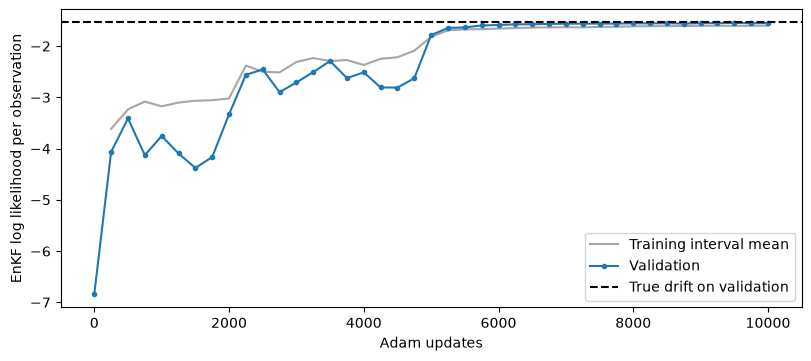

In [9]:
FILTER_REPLICATES = 4


def test_scores(drift):
    score = jax.jit(lambda keys: scores(drift, test_y, keys, EVAL_SOLVER_STEP))
    replicates = [
        score(jr.split(key, len(test_y)))
        for key in jr.split(likelihood_key, FILTER_REPLICATES)
    ]
    return np.mean(replicates, axis=0)


ref_ll = test_scores(reference_rhs)
nn_ll = test_scores(learned_drift)
for label, group in (
    ("All", slice(None)),
    ("Fresh", slice(0, TEST_PER_GROUP)),
    ("Burned-in", slice(TEST_PER_GROUP, None)),
):
    gap = ref_ll[group] - nn_ll[group]
    print(
        f"{label}: true {ref_ll[group].mean():.4f}, neural {nn_ll[group].mean():.4f}, "
        f"gap {gap.mean():.4f} ± {gap.std(ddof=1) / np.sqrt(len(gap)):.4f} SE nats/observation"
    )

ref_val = scores(reference_rhs, val_y, val_keys, TRAIN_SOLVER_STEP).mean()
iterations, validation = np.asarray(validation_history).T
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(
    iterations[1:],
    [-values.mean() for values in training_losses],
    color="0.65",
    label="Training interval mean",
)
ax.plot(iterations, validation, ".-", label="Validation")
ax.axhline(ref_val, color="black", ls="--", label="True drift on validation")
ax.set(xlabel="Adam updates", ylabel="EnKF log likelihood per observation")
ax.legend()
plt.show()

## Filter and forecast
Condition on four time units of noisy x. Propagate the final ensemble through eight more time units with no further observations. Repeat using only the final two units of the same prefix so both forecasts start at the same time.

In [10]:
FILTER_TIME = 4.0
SHORT_FILTER_TIME = 2.0
FORECAST_TIME = 8.0
FORECAST_PER_GROUP = 64
PREDICTION_INTERVAL = (0.05, 0.95)

fresh_key, burned_key, ensemble_key = jr.split(forecast_key, 3)
duration = FILTER_TIME + FORECAST_TIME
fresh, fresh_x = simulate_data(fresh_key, FORECAST_PER_GROUP, duration)
burned, burned_x = simulate_data(burned_key, FORECAST_PER_GROUP, duration, burn=BURN_IN)
cutoff = round(FILTER_TIME / DT)
obs_prefix = jnp.concatenate([fresh, burned])[:, : cutoff + 1]
true_x = np.concatenate([fresh_x, burned_x])[:, cutoff:]
forecast_keys = jr.split(ensemble_key, len(obs_prefix))


def forecasts(drift, prefixes):
    def forecast_one(prefix, key):
        filter_key, simulation_key = jr.split(key)
        posterior = filter_series(drift, prefix, filter_key, EVAL_SOLVER_STEP)

        def propagate(state):
            model = dynamics(drift, initial=dist.Delta(state, event_dim=1))
            return dsx.simulate(
                model,
                rng_key=simulation_key,
                predict_times=time_grid(FORECAST_TIME),
                simulator_config=dsx.configs.ODESimulatorConfig(
                    dt0=FORECAST_SOLVER_STEP
                ),
            ).states[0, :, 0]

        return jax.vmap(propagate)(posterior.ensemble[-1])

    return np.asarray(jax.jit(jax.vmap(forecast_one))(prefixes, forecast_keys))


short_prefix = obs_prefix[:, -len(time_grid(SHORT_FILTER_TIME)) :]
reference_fc = forecasts(reference_rhs, obs_prefix)
neural_fc = forecasts(learned_drift, obs_prefix)
reference_short = forecasts(reference_rhs, short_prefix)
neural_short = forecasts(learned_drift, short_prefix)
assert neural_fc.shape == (len(obs_prefix), ENSEMBLE_SIZE, true_x.shape[1])

## Check the long-run dynamics

Integrate each ODE with fixed-step Tsit5, saving at the observation cadence. Discard the first 50 time units and compare the marginal distribution and autocorrelation of $x$ over the next 1,000. Estimate the largest Lyapunov exponent separately by evolving a unit tangent vector along each trajectory and accumulating its growth between renormalizations.

### CPU cost of the long rollout

Each entry is the median of three warmed, synchronized CPU solves for 12 paired trajectories through time 1,050, saving every 0.02. Timings exclude compilation, training, plotting and the separate tangent calculation.

| Solver | Fixed step | True drift | Fitted neural drift |
|---|---:|---:|---:|
| Previous Euler–Maruyama scan | 0.001 | 0.797 s | 5.520 s |
| Diffrax Tsit5 | 0.001 | 0.380 s | 27.344 s |
| Diffrax Tsit5 | 0.01 | 0.041 s | 2.735 s |
| Diffrax Tsit5 (used here) | 0.02 | 0.022 s | 1.367 s |

Halving the Tsit5 step from 0.02 to 0.01 gave long-run $x$ SDs of 7.923 and 7.924 for the true drift and 7.817 and 7.816 for the neural drift. Individual chaotic paths separate over this horizon, so the comparison uses their pooled distributions.

In [11]:
ROLLOUT_COUNT = 12
ROLLOUT_BURN = 50.0
ROLLOUT_TIME = 1000.0
ROLLOUT_STEP = DT
TANGENT_STEP = 0.01
RENORMALIZE_EVERY = 10  # RK4 steps per unit-vector normalization.


def acf(x, maxlag):
    # Subtract the pooled stationary mean, preserving between-attractor offsets.
    centered = x.astype(float) - x.mean(dtype=float)
    n = centered.shape[1]
    auto = sum(
        correlate(row, row, mode="full", method="fft")[n - 1 : n + maxlag]
        for row in centered
    )
    auto /= n - np.arange(len(auto))
    return auto / max(auto[0], 1e-14)


def climate(drift, key, count, span):
    ts = time_grid(ROLLOUT_BURN + span)
    x = dsx.simulate(
        dynamics(drift),
        rng_key=key,
        predict_times=ts,
        n_simulations=count,
        simulator_config=dsx.configs.ODESimulatorConfig(dt0=ROLLOUT_STEP),
    ).states
    x = np.asarray(x)[:, round(ROLLOUT_BURN / DT) + 1 :, 0]
    assert x.shape == (count, round(span / DT)) and np.isfinite(x).all()
    return x

Estimate tangent growth along a simulated trajectory.

In [12]:
def exponents(drift, init, span):
    dt = TANGENT_STEP
    interval_duration = dt * RENORMALIZE_EVERY
    discard = round(ROLLOUT_BURN / interval_duration)

    def f(z):
        return drift(z, None, None)

    def step(z):
        a = f(z)
        b = f(z + dt / 2 * a)
        c = f(z + dt / 2 * b)
        d = f(z + dt * c)
        return z + dt / 6 * (a + 2 * b + 2 * c + d)

    def one(z):
        def interval(pair, _):
            def evolution(_, pair):
                return jax.jvp(step, (pair[0],), (pair[1],))

            z, v = jax.lax.fori_loop(0, RENORMALIZE_EVERY, evolution, pair)
            norm = jnp.linalg.norm(v)
            return (z, v / jnp.maximum(norm, 1e-12)), jnp.log(jnp.maximum(norm, 1e-12))

        _, growth = jax.lax.scan(
            interval,
            (z, jnp.array([1.0, 0.0, 0.0])),
            None,
            length=round((span + ROLLOUT_BURN) / interval_duration),
        )
        return growth[discard:].mean() / interval_duration

    return np.asarray(jax.jit(jax.vmap(one))(init))

Use paired initial draws for the long-run comparisons.

In [13]:
climate_key, tangent_key = jr.split(rollout_key)
reference_x = climate(reference_rhs, climate_key, ROLLOUT_COUNT, ROLLOUT_TIME)
learned_x = climate(learned_drift, climate_key, ROLLOUT_COUNT, ROLLOUT_TIME)
init = INITIAL.sample(tangent_key, (ROLLOUT_COUNT,))
true_exp = exponents(reference_rhs, init, ROLLOUT_TIME)
neural_exp = exponents(learned_drift, init, ROLLOUT_TIME)
assert np.isfinite(np.stack((true_exp, neural_exp))).all()
print(
    f"Retained {learned_x.size:,} x values per model. Each path contributes {learned_x.shape[1]:,}."
)
for label, x, lambdas in (
    ("True", reference_x, true_exp),
    ("Neural", learned_x, neural_exp),
):
    print(
        f"{label:6s}  x mean {x.mean():.3f}  SD {x.std():.3f}  "
        f"smallest within-path SD {x.std(axis=1).min():.3f}  "
        f"largest exponent {lambdas.mean():.3f} (range {lambdas.min():.3f}–{lambdas.max():.3f})"
    )

Retained 600,000 x values per model. Each path contributes 50,000.
True    x mean 0.004  SD 7.924  smallest within-path SD 7.908  largest exponent 0.903 (range 0.895–0.911)
Neural  x mean -1.003  SD 7.821  smallest within-path SD 7.791  largest exponent 0.881 (range 0.874–0.888)


## Evaluate the observed coordinate
Forecast validity ends at the first lead where the ensemble mean’s absolute x error reaches 40% of the reference invariant SD. Report both the median trajectory and the crossing of the pooled RMS error. The histogram tests the marginal, and the autocorrelation tests temporal dependence.

In [14]:
ERROR_THRESHOLD = 0.40
MAX_ACF_LAG = 10.0
HISTOGRAM_BINS = 55


def forecast_validity(ensemble):
    normalized_error = np.abs(ensemble.mean(axis=1) - true_x) / reference_x.std()

    def first_crossing(errors):
        exceed = errors >= ERROR_THRESHOLD
        return (
            np.where(exceed.any(axis=-1), exceed.argmax(axis=-1), errors.shape[-1] - 1)
            * DT
            * true_exp.mean()
        )

    roots = first_crossing(normalized_error)
    pooled = first_crossing(np.sqrt((normalized_error**2).mean(axis=0)))
    return roots, pooled


for label, ensemble in (
    (f"True, {SHORT_FILTER_TIME:g}-unit history", reference_short),
    (f"True, {FILTER_TIME:g}-unit history", reference_fc),
    (f"Neural, {SHORT_FILTER_TIME:g}-unit history", neural_short),
    (f"Neural, {FILTER_TIME:g}-unit history", neural_fc),
):
    v, pooled = forecast_validity(ensemble)
    print(
        f"{label}   median {np.median(v):.3f} Lyapunov times, {sum(v > 1)}/{len(v)} exceed one, "
        f"pooled RMS crosses at {pooled:.3f}."
    )
lag = min(round(MAX_ACF_LAG / DT), learned_x.shape[1] - 2)
ref_acf, nn_acf = acf(reference_x, lag), acf(learned_x, lag)
w1 = (
    np.abs(np.sort(learned_x.ravel()) - np.sort(reference_x.ravel())).mean()
    / reference_x.std()
)
print(
    f"Marginal Wasserstein distance {w1:.3f} reference SD. Autocorrelation RMSE {np.sqrt(np.mean((ref_acf - nn_acf) ** 2)):.3f}."
)

True, 2-unit history   median 1.283 Lyapunov times, 79/128 exceed one, pooled RMS crosses at 0.849.
True, 4-unit history   median 1.310 Lyapunov times, 85/128 exceed one, pooled RMS crosses at 0.885.
Neural, 2-unit history   median 1.238 Lyapunov times, 82/128 exceed one, pooled RMS crosses at 0.813.
Neural, 4-unit history   median 1.265 Lyapunov times, 79/128 exceed one, pooled RMS crosses at 0.795.
Marginal Wasserstein distance 0.132 reference SD. Autocorrelation RMSE 0.037.


### Forecasts, invariant x density and temporal dependence

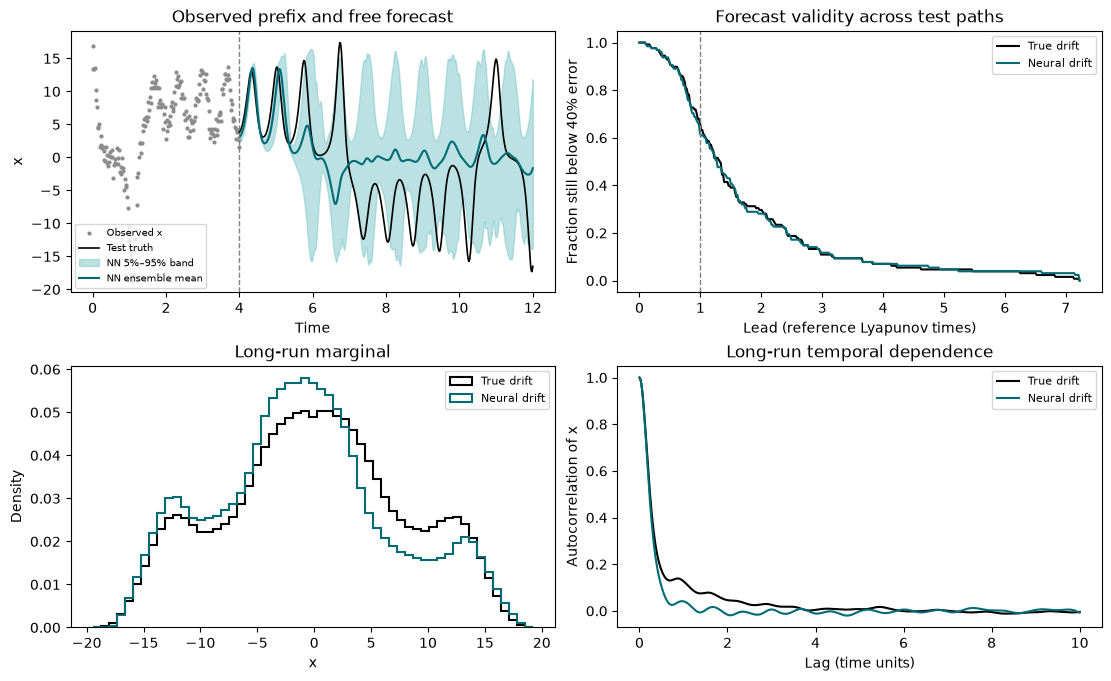

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.7), layout="constrained")
past, lead = DT * np.arange(cutoff + 1), np.asarray(time_grid(FORECAST_TIME))
i = FORECAST_PER_GROUP  # First prespecified burned-in test trajectory.
ax = axes[0, 0]
ax.scatter(past, obs_prefix[i], s=4, color="0.55", label="Observed x")
ax.plot(FILTER_TIME + lead, true_x[i], color="black", lw=1.2, label="Test truth")
ax.fill_between(
    FILTER_TIME + lead,
    *np.quantile(neural_fc[i], PREDICTION_INTERVAL, axis=0),
    color="#83c9cb",
    alpha=0.55,
    label=f"NN {PREDICTION_INTERVAL[0]:.0%}–{PREDICTION_INTERVAL[1]:.0%} band",
)
ax.plot(
    FILTER_TIME + lead,
    neural_fc[i].mean(axis=0),
    color="#006b75",
    label="NN ensemble mean",
)
ax.axvline(FILTER_TIME, color="0.5", ls="--", lw=1)
ax.set(xlabel="Time", ylabel="x", title="Observed prefix and free forecast")
ax.legend(fontsize=7)
ax = axes[0, 1]
for label, ensemble, color in (
    ("True drift", reference_fc, "black"),
    ("Neural drift", neural_fc, "#006b75"),
):
    roots, _ = forecast_validity(ensemble)
    t = lead * true_exp.mean()
    ax.plot(t, (roots[:, None] > t).mean(axis=0), color=color, label=label)
ax.axvline(1, color="0.5", ls="--", lw=1)
ax.set(
    xlabel="Lead (reference Lyapunov times)",
    ylabel=f"Fraction still below {ERROR_THRESHOLD:.0%} error",
    title="Forecast validity across test paths",
)
ax.legend(fontsize=8)
edges = np.histogram_bin_edges(
    np.concatenate((reference_x.ravel(), learned_x.ravel())), bins=HISTOGRAM_BINS
)
for label, x, corr, color in (
    ("True drift", reference_x, ref_acf, "black"),
    ("Neural drift", learned_x, nn_acf, "#006b75"),
):
    axes[1, 0].hist(
        x.ravel(),
        bins=edges,
        density=True,
        histtype="step",
        lw=1.5,
        label=label,
        color=color,
    )
    axes[1, 1].plot(DT * np.arange(len(corr)), corr, label=label, color=color)
axes[1, 0].set(xlabel="x", ylabel="Density", title="Long-run marginal")
axes[1, 1].set(
    xlabel="Lag (time units)",
    ylabel="Autocorrelation of x",
    title="Long-run temporal dependence",
)
for ax in axes[1]:
    ax.legend(fontsize=8)
plt.show()

## How sensitive is the fit to the global seed?

The table records the earlier seven-seed experiment, which computed long-run $x$ moments with Euler integration at step 0.001. The cells above use Tsit5 and report fresh moments for the selected seed. The reference long-run SD sets the forecast error threshold, so the reported crossing time can also shift slightly between solvers.

Each seed changes the simulated data, initialization, optimizer draws, filter ensembles and evaluation trajectories. All seven runs used the same settings and the same validation rule. The seed sweep includes five development seeds and two additional seeds (5 and 6) evaluated after fixing the rule. Each forecast column reports the median over 128 independent trajectories. The likelihood gap is the true-drift score minus the neural-drift score, in nats per observed x.

| Seed | EnKF likelihood gap | NN forecast (Lyapunov times) | True-drift forecast | NN x mean | NN x SD | NN largest exponent |
|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.0083 | 1.265 | 1.310 | -0.897 | 7.865 | 0.881 |
| 1 | 0.0059 | 1.190 | 1.417 | -0.342 | 7.806 | 0.720 |
| 2 | 0.0031 | 1.435 | 1.526 | -0.708 | 7.913 | 0.899 |
| 3 | 0.0049 | 1.436 | 1.427 | 0.128 | 7.884 | 0.889 |
| 4 | 0.0023 | 1.115 | 1.315 | -0.771 | 7.821 | 0.868 |
| 5 | 0.0016 | 1.179 | 1.297 | -0.970 | 7.838 | 0.885 |
| 6 | 0.0062 | 1.194 | 1.266 | -0.619 | 7.825 | 0.860 |

The two-pilot fit exceeded one reference Lyapunov time on all seven seed-level medians. Across seeds, 74 to 94 of the 128 individual forecasts passed that threshold. The pooled RMS error reached 40% earlier, at 0.418 to 0.836 Lyapunov times. The true long-run x SD was about 7.95. The neural fit retains some long-run mean bias. A positive average exponent summarizes the collection of starts. Individual starts can behave differently. For seed 1 the smallest estimated exponent was −0.058.

A single Adam run on 1.5-unit series collapsed for one of the five development seeds. Shortening series to 0.8 and using a batch of 16 avoided that collapse on seeds 0–6, but the median forecast validity for seed 6 was 0.913. These comparisons motivated the additional pilot. The seed table reports a finite set of reproducible checks.